# Adversarial Search: Solving Tic-Tac-Toe with Monte Carlo Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* We enhance Pure Monte Carlo Search by using the upper confidence bound (UCB1) selection policy. That is, we use UCB1 to determine for which action to perform the next playout. This will allow the algorithm to focus on actions here it needs to collect more information. Note that complete Upper Confidence Bounds applied to Trees (UCT) creates a tree and the expand step in the code needs to be added. The tree branch for the chosen move is preserved and used for future moves.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py). 

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

In [ ]:
# Hàm phụ: cho tác tử đấu random_player 100 ván khi đi trước (x) và 100 ván khi đi sau (o), đo thời gian mỗi nước
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tictactoe import other
np.random.seed(0)

def danh_gia(agent, ten, N = 100):
    dong = []
    for vai in 'xo':
        t = []
        def dem(board, player = 'x'):
            s = time.perf_counter(); a = agent(board, player); t.append(time.perf_counter() - s); return a
        r = play(dem, random_player, N) if vai == 'x' else play(random_player, dem, N)
        dong.append([ten, 'đi trước' if vai == 'x' else 'đi sau', r[vai], r['d'], r[other(vai)], round(1000 * np.mean(t), 1)])
    return pd.DataFrame(dong, columns = ['Tác tử', 'Vai', 'Thắng', 'Hòa', 'Thua', 'ms/nước'])

def ve(bang, tieu_de):
    nhan = bang['Tác tử'] + ' (' + bang['Vai'] + ')'
    ax = bang[['Thắng', 'Hòa', 'Thua']].set_index(nhan).plot.barh(stacked = True, color = ['#2a78d6', '#c3c2b7', '#eb6834'], figsize = (8, 0.45 * len(bang) + 1.3))
    ax.set_xlabel('số ván'); ax.set_ylabel(''); ax.set_title(tieu_de); ax.invert_yaxis()
    ax.legend(ncol = 3, loc = 'upper center', bbox_to_anchor = (0.5, -0.2))
    plt.show()

In [ ]:
# Bốn trạng thái kiểm thử (đến lượt x đi)
def ban(x = (), o = ()):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b

tests = {'A: x sắp thắng': ban((0, 4), (1, 3)), 'B: x phải đi ô 7': ban((0, 2), (1, 4)),
         'C: bất lợi': ban((2,), (0, 8)), 'D: bàn rỗng': ban()}

# Monte Carlo Search with Upper Confidence Bound

See AIMA page 163. 

We enhance pure Monte Carlo Search by using UCB1 as a __selection policy__. This can be seen as a 
restricted version of UTC: 
* Only build a tree of depth 1 and use the UBC1 selection policy.
* Use a random playout policy.


__Note on the playout policy:__ We use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with a good __playout policy__ (e.g., manually created heuristics or a neural [network learned by self-play using reinforcement learning](https://towardsdatascience.com/how-to-teach-an-ai-to-play-games-deep-reinforcement-learning-28f9b920440a)).

## Simulate playouts

In [5]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

1
1
1


## Upper Confidence Bound Applied to Trees (Restricted to Depth 1)

In [6]:
import pandas as pd
import math

DEBUG = 1

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

In [7]:
board = empty_board()
display(board)

%timeit -n 1 -r 1 UCT_depth1(board, N = 1000)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

   action  total utility  # of playouts      UCB1
0       0             60            149  0.707187
1       1             16             65  0.707181
2       2             51            133  0.705757
3       3             26             86  0.703132
4       4            123            259  0.705862
5       5             -1             26  0.690487
6       6             39            110  0.708940
7       7             16             66  0.699946
8       8             42            106  0.757246

Best action: 4
795 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


## Some Tests

### x is about to win (play 8)

Board:


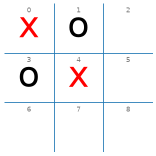


   action  total utility  # of playouts      UCB1
0       2             18             21  1.519402
1       5              8             13  1.457102
2       6             17             20  1.528614
3       7              8             13  1.457102
4       8             33             33  1.528300

Best action: 8
19.1 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board)

### o is about to win

Board:


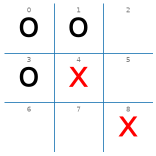

   action  total utility  # of playouts      UCB1
0       2            -23            115  0.146605
1       5            -14             20  0.131129
2       6             27            851  0.159142
3       7            -12             14  0.136246

Best action: 6
172 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [9]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### x can draw if it chooses 7

Board:


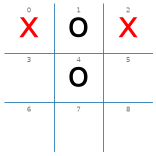

   action  total utility  # of playouts      UCB1
0       3            -12             58  0.281159
1       5            -12             55  0.283008
2       6            -12             29  0.276422
3       7            122            785  0.288077
4       8            -11             73  0.284348

Best action: 7
313 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [10]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### Empty board: Only a draw an be guaranteed

Board:


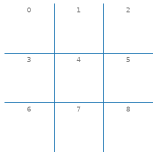

   action  total utility  # of playouts      UCB1
0       0             -2              3  1.085507
1       1              8             16  1.258714
2       2              6             15  1.183596
3       3              6             15  1.183596
4       4              7             16  1.196214
5       5             -1              4  1.267427
6       6             -2              4  1.017427
7       7              5             12  1.292754
8       8              6             15  1.183596

Best action: 1
62.3 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


   action  total utility  # of playouts      UCB1
0       0             49            188  0.561651
1       1             66            229  0.560948
2       2            104            313  0.565556
3       3             51            191  0.565655
4       4           1303           2679  0.566116
5       5             13             94  0.563994
6       6            161            438  0.564789
7       7             35            152  0.565029
8       8            294            716  0.564858

Best action: 4
3.37 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [11]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%timeit -n1 -r1 UCT_depth1(board, N = 100)
%timeit -n1 -r1 UCT_depth1(board, N = 5000)

### A bad situation

Board:


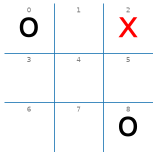


   action  total utility  # of playouts      UCB1
0       1             -4              4  0.517427
1       3             -4              4  0.517427
2       4             22             78  0.625681
3       5             -4              4  0.517427
4       6             -4              4  0.517427
5       7             -4              6  0.572307

Best action: 4


4

In [12]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)


print()
display(UCT_depth1(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [13]:
def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

In [14]:
DEBUG = 0
print("UCB1 (10) vs. random:")
%timeit -n1 -r1 display(play(ucb1_10_player, random_player))

print()
print("random vs. UCB1 (10):")
%timeit -n1 -r1 display(play(random_player, ucb1_10_player))

UCB1 (10) vs. random:


{'x': 88, 'o': 9, 'd': 3}

1.28 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (10):


{'x': 12, 'o': 81, 'd': 7}

977 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [15]:
DEBUG = 0
print("UCB1 (100) vs. random:")
%timeit -n 1 -r 1 display(play(ucb1_100_player, random_player))

print()
print("random vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(random_player, ucb1_100_player))

UCB1 (100) vs. random:


{'x': 98, 'o': 0, 'd': 2}

11 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (100):


{'x': 2, 'o': 86, 'd': 12}

8.41 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [16]:
DEBUG = 0
print("UCB1 (100) vs. UCB1 (10):")
%timeit -n 1 -r 1 display(play(ucb1_100_player, ucb1_10_player))

print()
print("UCB1 (10) vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(ucb1_10_player, ucb1_100_player))

UCB1 (100) vs. UCB1 (10):


{'x': 92, 'o': 1, 'd': 7}

11 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

UCB1 (10) vs. UCB1 (100):


{'x': 29, 'o': 42, 'd': 29}

8.7 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [ ]:
# UCT_depth1 với N = 10, 100, 1000: nước được chọn trong 10 lần chạy
DEBUG = 0
dong = []
for ten, b in tests.items():
    for N in (10, 100, 1000):
        chon = [UCT_depth1(b, N) for _ in range(10)]
        dong.append([ten, N, ' '.join(str(c) for c in chon)])
display(pd.DataFrame(dong, columns = ['Trạng thái', 'N', 'Nước chọn trong 10 lần']))

,Trạng thái,N,Nước chọn trong 10 lần
0,A: x sắp thắng,10,2 5 2 6 2 6 2 2 5 2
1,A: x sắp thắng,100,8 8 8 8 8 8 8 8 8 8
2,A: x sắp thắng,1000,8 8 8 8 8 8 8 8 8 8
3,B: x phải đi ô 7,10,3 5 3 3 3 3 5 7 7 3
4,B: x phải đi ô 7,100,7 7 7 7 6 7 7 7 7 7
5,B: x phải đi ô 7,1000,7 7 7 7 7 7 7 7 7 7
6,C: bất lợi,10,1 1 3 6 3 5 4 4 5 3
7,C: bất lợi,100,4 4 4 4 4 6 4 4 4 4
8,C: bất lợi,1000,4 4 4 4 4 4 4 4 4 4
9,D: bàn rỗng,10,2 2 1 0 1 0 0 1 0 1


**Nhận xét:** Giống pmcs, UCB1 ổn định hơn khi N tăng: N = 10 lẫn lộn, N = 100 hầu như luôn đúng (A: 10/10 lần ô 8, B: 9/10 lần ô 7), N = 1000 luôn cùng một nước (kể cả bàn rỗng luôn chọn ô giữa 4). So với pmcs ở cùng N = 100, UCB1 chọn đúng đều hơn (B: 9/10 so với 7/10).

,Tác tử,Vai,Thắng,Hòa,Thua,ms/nước
0,UCB1 N = 10,đi trước,80,6,14,2.6
1,UCB1 N = 10,đi sau,71,15,14,2.0
2,UCB1 N = 100,đi trước,99,1,0,27.1
3,UCB1 N = 100,đi sau,84,7,9,19.5


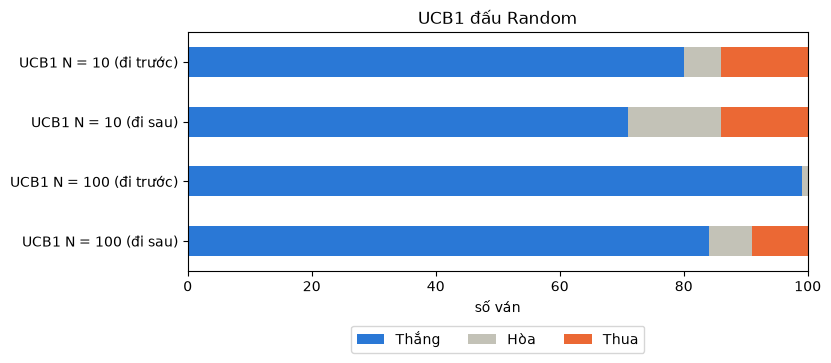

In [ ]:
# UCB1 đấu Random
DEBUG = 0
bang = pd.concat([danh_gia(ucb1_10_player, 'UCB1 N = 10'), danh_gia(ucb1_100_player, 'UCB1 N = 100')], ignore_index = True)
display(bang)
ve(bang, 'UCB1 đấu Random')

**Nhận xét:** N = 10 thua 28 ván, N = 100 thua 9 ván khi đấu Random (đi trước 99 thắng). UCB1 cân bằng *exploitation* và *exploration* bằng công thức `u/n + C·sqrt(ln(n_cha)/n)`: nước có điểm trung bình tốt được thử nhiều hơn, nhưng nước ít được thử có số hạng thứ hai lớn nên vẫn được xét lại. Khi N tăng quyết định ổn định hơn (xem bảng trên).